### Question 1. Sinusoidal Positional Encoding: Mathematical Derivation and Implementation

**c. Python implementation** Implement the function below. Use seq_len = 20 and d_model = 16; visualize the encoding matrix using Matplotlib. 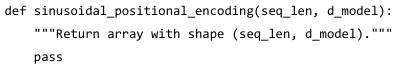

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Function for sinusoidal positional encoding
def sinusoidal_positional_encoding(seq_len, d_model):
    """Return array with shape (seq_len, d_model)."""

    # Initialize positional encoding matrix
    PE = np.zeros((seq_len, d_model))

    for pos in range(seq_len):
        for i in range(d_model // 2):
            # Calculate angle frequencies
            angle = pos / (10000 ** (2 * i / d_model))
            
            # Apply sine to even dimensions
            PE[pos, 2 * i] = np.sin(angle)
            
            # Apply cosine to odd dimensions
            PE[pos, 2 * i + 1] = np.cos(angle)

    return PE

Encoding matrix shape: (20, 16)
Encoding matrix:
 [[ 0.00000000e+00  1.00000000e+00  0.00000000e+00  1.00000000e+00
   0.00000000e+00  1.00000000e+00  0.00000000e+00  1.00000000e+00
   0.00000000e+00  1.00000000e+00  0.00000000e+00  1.00000000e+00
   0.00000000e+00  1.00000000e+00  0.00000000e+00  1.00000000e+00]
 [ 8.41470985e-01  5.40302306e-01  3.10983593e-01  9.50415280e-01
   9.98334166e-02  9.95004165e-01  3.16175064e-02  9.99500042e-01
   9.99983333e-03  9.99950000e-01  3.16227239e-03  9.99995000e-01
   9.99999833e-04  9.99999500e-01  3.16227761e-04  9.99999950e-01]
 [ 9.09297427e-01 -4.16146837e-01  5.91127117e-01  8.06578410e-01
   1.98669331e-01  9.80066578e-01  6.32033979e-02  9.98000667e-01
   1.99986667e-02  9.99800007e-01  6.32451316e-03  9.99980000e-01
   1.99999867e-03  9.99998000e-01  6.32455490e-04  9.99999800e-01]
 [ 1.41120008e-01 -9.89992497e-01  8.12648897e-01  5.82753611e-01
   2.95520207e-01  9.55336489e-01  9.47260913e-02  9.95503374e-01
   2.99955002e-02  9.99

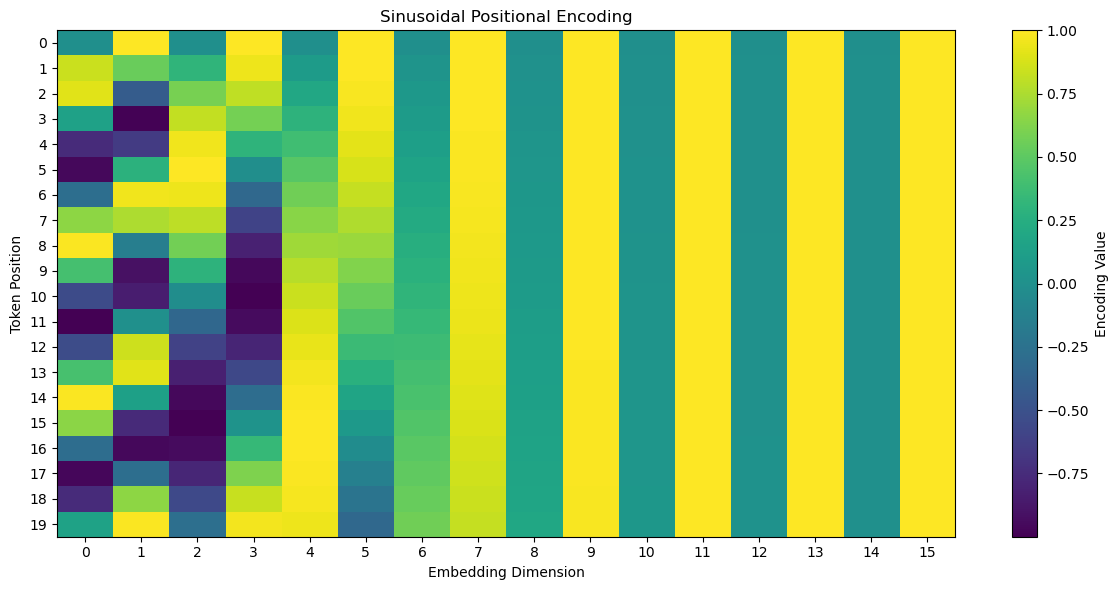

In [2]:
# Define parameters
seq_len = 20
d_model = 16

# Generate positional encoding
PE = sinusoidal_positional_encoding(seq_len, d_model)

# Print matrix shape
print("Encoding matrix shape:", PE.shape)

# Print matrix
print("Encoding matrix:\n", PE)

# Visualize positional encoding
plt.figure(figsize=(12, 6))

plt.imshow(PE, aspect='auto', cmap='viridis')

plt.colorbar(label='Encoding Value')

plt.xlabel('Embedding Dimension')
plt.ylabel('Token Position')

plt.title('Sinusoidal Positional Encoding')

plt.xticks(range(d_model))
plt.yticks(range(seq_len))

plt.tight_layout()
plt.show()

### Question 2. Scaled Dot-Product Self-Attention from Scratch

**c. Python implementation** Implement softmax manually with NumPy (no external softmax). 
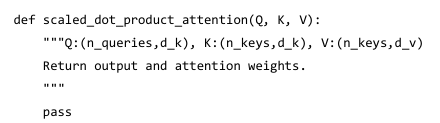

In [3]:
import numpy as np
def scaled_dot_product_attention(Q, K, V):
    """
    Q: (n_queries, d_k)
    K: (n_keys, d_k)
    V: (n_keys, d_v)

    Return output and attention weights.
    """
    
    # Step 1: Calculate scale the attention scores
    d_k = K.shape[1]
    scores = scores = np.matmul(Q, K.T) / np.sqrt(d_k)

    # Step 2: Apply softmax manually (row-wise)
    # Subtract maximum for numerical stability
    exp_scores = np.exp(scores - np.max(scores, axis=1, keepdims=True))

    attention_weights = (exp_scores / np.sum(exp_scores, axis=1, keepdims=True))

    # Step 3: Calculate final attention output
    output = np.matmul(attention_weights, V) # matrix multiplication

    return output, attention_weights

In [4]:
# Define Q, K and V input matrices
np.random.seed(42)

Q = np.random.rand(3, 4)
K = np.random.rand(5, 4)
V = np.random.rand(5, 6)

In [5]:
# Call the attention function
output, attention_weights = scaled_dot_product_attention(Q, K, V)

In [6]:
# Display results
print("Attention Weights:")
print(np.round(attention_weights, 3))

print("\nFinal Attention Output:")
print(np.round(output, 3))

print("\nOutput Shape:", output.shape)
print("Weights Shape:", attention_weights.shape)

Attention Weights:
[[0.179 0.212 0.182 0.243 0.184]
 [0.191 0.198 0.202 0.223 0.186]
 [0.194 0.195 0.193 0.249 0.17 ]]

Final Attention Output:
[[0.456 0.608 0.492 0.622 0.378 0.518]
 [0.433 0.612 0.49  0.618 0.381 0.492]
 [0.452 0.624 0.512 0.631 0.386 0.507]]

Output Shape: (3, 6)
Weights Shape: (3, 5)


Verify each row of attention weights sums to 1 and compare Python and handwritten outputs.

In [7]:
# Verify row-wise sum of attention weights
row_sums = np.sum(attention_weights, axis=1)

print("Sum of each attention row:")
print(row_sums)

# Check whether each row sums to 1
print("\nVerification:")
print(np.allclose(row_sums, 1.0)) # checks whether all values in row_sums are approximately equal to 1.0

Sum of each attention row:
[1. 1. 1.]

Verification:
True


### Question 3. Learnable Query, Key, and Value Projections

**c. Python implementation** Implement projections followed by scaled dot-product self
attention.

The program first computes the three projections, calculates the scaled similarity scores, applies softmax row-wise, and multiplies the attention weights by V to obtain the final output.

In [8]:
import numpy as np

def self_attention(X, W_Q, W_K, W_V):
    """Compute Q, K, V projections and attention."""

    # Step 1: Compute Query, Key, and Value
    Q = np.matmul(X, W_Q)
    K = np.matmul(X, W_K)
    V = np.matmul(X, W_V)

    # Step 2: Calculate scaled dot-product  attention scores
    d_k = K.shape[1]
    scores = np.matmul(Q, K.T) / np.sqrt(d_k)

    # Step 3: Apply row-wise softmax manually
    scores = scores - np.max(scores, axis=1, keepdims=True)
    attention_weights = np.exp(scores)
    attention_weights /= np.sum(attention_weights, axis=1, keepdims=True)

    # Step 4: Calculate final attention output
    output = np.matmul(attention_weights, V)
    
    return Q, K, V, attention_weights, output

In [9]:
# Example input
np.random.seed(42)

seq_len = 5
d_model = 8
d_k = 4
d_v = 4

# Input embedding matrix
X = np.random.rand(seq_len, d_model)

# Learnable weight matrices
W_Q = np.random.rand(d_model, d_k)
W_K = np.random.rand(d_model, d_k)
W_V = np.random.rand(d_model, d_v)

In [10]:
Q, K, V, attention_weights ,output= self_attention(X, W_Q, W_K, W_V)

print("Query(Q):\n", Q)
print("Key(K):\n", K)
print("Value(V):\n", V)
print("Attention weights:\n", attention_weights)
print("Attention output:\n", output)

print("Output Shape:\n", output.shape)
print("Attention Weights Shape:", attention_weights.shape)

Query(Q):
 [[1.40969136 2.44558697 2.19031623 2.27941988]
 [1.40002721 2.13891685 1.22213224 2.35381898]
 [0.90043241 1.516631   1.2343355  1.70883272]
 [1.10500368 1.86980114 1.04408566 2.18245006]
 [1.83085806 2.45466094 2.24866976 2.81667136]]
Key(K):
 [[1.86797014 1.76404968 1.69723488 1.44649173]
 [1.86973445 1.57757499 1.71872387 1.95142145]
 [1.68298606 1.37616771 1.06188877 1.21884998]
 [1.82423796 1.39581455 1.22080503 1.3617469 ]
 [2.5331135  1.75938055 1.5629518  1.29730908]]
Value(V):
 [[1.98486058 1.39832049 2.44535237 1.84133618]
 [2.24997944 1.3933746  2.01783827 1.48342174]
 [1.60358964 1.40039552 1.58650946 1.21866677]
 [1.70606341 1.35000898 1.64089968 1.21775947]
 [2.14931034 1.83318225 2.51221023 1.89146824]]
Attention weights:
 [[0.24088259 0.34951288 0.05062142 0.08022692 0.27875619]
 [0.2235024  0.33650669 0.06728618 0.09890203 0.2738027 ]
 [0.23040709 0.31228552 0.08786592 0.11844821 0.25099325]
 [0.22431938 0.33093449 0.07889749 0.11032748 0.25552116]
 [0.22523

### Question 4. Causal Self-Attention and Masking

**c. Python implementation** Construct the mask using NumPy; do not use prebuilt attention or masking functions.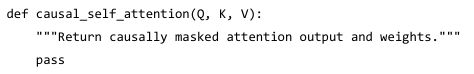

In [11]:
import numpy as np

def causal_self_attention(Q, K, V):
    """Return causally masked attention output and weights."""

    # Step 1: Calculate scaled attention scores
    d_k = K.shape[1]
    scores = np.matmul(Q, K.T) / np.sqrt(d_k)

    # Step 2: Construct the causal mask manually
    n = Q.shape[0]
    mask = np.triu(np.ones((seq_len, seq_len)), k=1)  

    # Step 3: Apply the mask (future positions get -infinity)
    scores = np.where(mask == 1, -np.inf, scores)

    # Step 4: Apply softmax row-wise
    exp_scores = np.exp(scores - np.max(scores, axis=1, keepdims=True))
    attention_weights = exp_scores / np.sum(exp_scores, axis=1, keepdims=True)

    # Step 5: Calculate the attention output
    output = np.matmul(attention_weights, V)

    return output, attention_weights

In [12]:
# Example input
np.random.seed(42)

seq_len = 5
d_k = 4
d_v = 4

Q = np.random.rand(seq_len, d_k)
K = np.random.rand(seq_len, d_k)
V = np.random.rand(seq_len, d_v)

In [13]:
# Apply causal self-attention
output, weights = causal_self_attention(Q, K, V)

In [14]:
# Display results
print("Causal Attention weights:")
print(np.round(weights, 4))

print("\nAttention output:")
print(np.round(output, 4))

print("\nOutput Shape:", output.shape)
print("Weights Shape:", weights.shape)

# Verify row sums
print("\nRow sums:", np.sum(weights, axis=1))

Causal Attention weights:
[[1.     0.     0.     0.     0.    ]
 [0.4751 0.5249 0.     0.     0.    ]
 [0.316  0.4067 0.2773 0.     0.    ]
 [0.2524 0.2546 0.2505 0.2425 0.    ]
 [0.1782 0.2064 0.1804 0.2501 0.185 ]]

Attention output:
[[0.122  0.4952 0.0344 0.9093]
 [0.1938 0.583  0.1799 0.705 ]
 [0.2954 0.4772 0.4065 0.7138]
 [0.4615 0.5569 0.4759 0.7796]
 [0.4251 0.5183 0.4032 0.6999]]

Output Shape: (5, 4)
Weights Shape: (5, 5)

Row sums: [1. 1. 1. 1. 1.]


### Question 5. Cross-Attention in Encoder–Decoder Transformers

**c. Python implementation** Implement decoder-to-encoder cross-attention.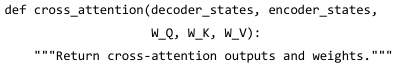

The function accepts the decoder and encoder hidden states along with their projection matrices. In a real Transformer Q, K and V are calculated from those states as shown in the function

In [15]:
import numpy as np

def cross_attention(decoder_states, encoder_states,W_Q, W_K, W_V):
    """Return cross-attention outputs and weights."""

    # 1. Generate query, key, and value matrices
    Q = np.matmul(decoder_states, W_Q)
    K = np.matmul(encoder_states, W_K)
    V = np.matmul(encoder_states, W_V)

    # 2. Calculate scaled dot-product attention scores
    d_k = K.shape[1]
    scores = np.matmul(Q, K.T) / np.sqrt(d_k)

    # 3. Apply row-wise softmax manually
    exp_scores = np.exp(scores - np.max(scores, axis=1, keepdims=True))
    attention_weights = exp_scores / np.sum(exp_scores, axis=1, keepdims=True)

    # Step 4: Calculate final cross-attention output
    output = np.matmul(attention_weights, V)

    return output, attention_weights

In [16]:
# Example input
np.random.seed(42)

d_model = 8
d_k = 4
d_v = 4

# Decoder and encoder hidden states
decoder_states = np.random.rand(3, d_model)
encoder_states = np.random.rand(5, d_model)

# Learnable weight matrices
W_Q = np.random.rand(d_model, d_k)
W_K = np.random.rand(d_model, d_k)
W_V = np.random.rand(d_model, d_v)

In [17]:
# Apply cross-attention
output, weights = cross_attention(decoder_states, encoder_states, W_Q, W_K, W_V)

In [18]:
print("Cross-Attention weights:")
print(np.round(weights, 4))

print("Cross-attention output:")
print(np.round(output, 4))

print("\nOutput Shape:", output.shape)
print("Weights Shape:", weights.shape)

Cross-Attention weights:
[[0.0029 0.016  0.0022 0.9779 0.0011]
 [0.0063 0.0259 0.0043 0.9606 0.0028]
 [0.0118 0.0414 0.0085 0.9328 0.0055]]
Cross-attention output:
[[2.2814 2.4803 3.3175 2.8381]
 [2.2687 2.4651 3.3027 2.819 ]
 [2.2482 2.4403 3.2786 2.7876]]

Output Shape: (3, 4)
Weights Shape: (3, 5)


### Question 6. Multi-Head Attention: Parallel Attention Subspaces

**c. Python implementation** Split projected representations into heads, compute independent attention, concatenate, and apply the output projection. 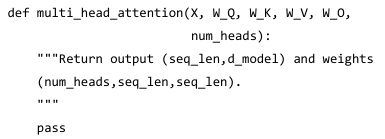

In [19]:
import numpy as np

def multi_head_attention(x, W_Q, W_K, W_V, W_O, num_heads):
    """
    Return output (seq_len, d_model) and weights
    (num_heads, seq_len, seq_len).
    """
   
    # Step 1: Project input into Q, K and V
    Q = np.matmul(X, W_Q)
    K = np.matmul(X, W_K)
    V = np.matmul(X, W_V)

    # Step 2: Get dimensions
    seq_len, d_model = X.shape
    head_dim = d_model // num_heads

    assert d_model % num_heads == 0, "d_model must be divisible by num_heads"

    # Step 3: Split Q, K, V into multiple heads
    Q = Q.reshape(seq_len, num_heads, head_dim).transpose(1, 0, 2)
    K = K.reshape(seq_len, num_heads, head_dim).transpose(1, 0, 2)
    V = V.reshape(seq_len, num_heads, head_dim).transpose(1, 0, 2)

    # Step 4: Calculate scaled dot-product attention
    scores = np.matmul(Q, K.transpose(0, 2, 1)) / np.sqrt(head_dim)


    # Step 5: Apply Softmax manually
    exp_scores = np.exp(scores - np.max(scores, axis=-1, keepdims=True))
    attention_weights = exp_scores / np.sum(exp_scores, axis=-1, keepdims=True)

    # Step 6: Compute independent attention for each head
    head_outputs = np.matmul(attention_weights, V)

    # Step 7: Concatenate all heads
    concatenated = head_outputs.transpose(1, 0, 2).reshape(seq_len, d_model)

    # Step 8: Apply output projection
    output = np.matmul(concatenated, W_O)

    # Return output and attention weights
    return output, attention_weights

In [20]:
# Example input
np.random.seed(42)

seq_len = 5
d_model = 8
num_heads = 2

# Input embedding matrix
X = np.random.rand(seq_len, d_model)

# Weight matrices
W_Q = np.random.rand(d_model, d_model)
W_K = np.random.rand(d_model, d_model)
W_V = np.random.rand(d_model, d_model)
W_O = np.random.rand(d_model, d_model)

In [21]:
# Apply multi-head attention
output, weights = multi_head_attention(X, W_Q, W_K, W_V, W_O, num_heads)


In [22]:
# Display results
print("Attention Weights:\n", weights)
print("\nAttention Output:\n", output)

print("\nOutput Shape:", output.shape)
print("Attention Weights Shape:", weights.shape)

Attention Weights:
 [[[0.27161303 0.17195967 0.05911059 0.1219517  0.37536502]
  [0.2636683  0.16915652 0.04531968 0.10942925 0.41242626]
  [0.25970279 0.17826181 0.07140829 0.13329207 0.35733503]
  [0.2678854  0.17706552 0.05391089 0.119274   0.38186419]
  [0.28019894 0.16630055 0.04609099 0.10877689 0.39863262]]

 [[0.12659354 0.05007049 0.02046852 0.04806321 0.75480424]
  [0.13786856 0.06661756 0.02799811 0.06321141 0.70430435]
  [0.1610959  0.09758533 0.04711512 0.0921655  0.60203816]
  [0.13548626 0.07230625 0.03024588 0.06926832 0.69269329]
  [0.10179343 0.041203   0.01259139 0.03571401 0.80869817]]]

Attention Output:
 [[13.36863832 11.91353707  7.28890304  6.12578524  9.71732974  7.18091709
   7.28328939 10.49024154]
 [13.39262692 11.92200051  7.30471836  6.13309476  9.69446515  7.19817653
   7.27067274 10.48230629]
 [13.11804511 11.6522504   7.15292481  6.00186892  9.47654704  7.02914167
   7.12051658 10.24953941]
 [13.30235441 11.83922115  7.25378703  6.09303696  9.63634202  

### Question 7. Numerical Stability and Attention Temperature

**b. Python implementation** Implement stable softmax; test [1000,1001,1002] against direct exponentiation. 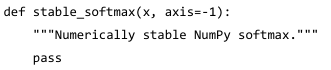

In [23]:
import numpy as np

def stable_softmax(x, axis=-1):
    """Numerically stable NumPy softmax."""

    # Step 1: Subtract maximum value
    x_shifted = x - np.max(x, axis=axis, keepdims=True)

    # Step 2: Calculate exponentials
    exp_x = np.exp(x_shifted)

    # Step 3: Normalize probabilities
    return exp_x / np.sum(exp_x, axis=axis, keepdims=True)

In [24]:
# Test input
x = np.array([1000, 1001, 1002])

In [25]:
# Numerically stable softmax
stable_result = stable_softmax(x)

# Direct exponentiation(unstable)
direct_result = np.exp(x) / np.sum(np.exp(x))

C:\Users\User\AppData\Local\Temp\ipykernel_13404\3886390076.py:5: RuntimeWarning: overflow encountered in exp
  direct_result = np.exp(x) / np.sum(np.exp(x))
C:\Users\User\AppData\Local\Temp\ipykernel_13404\3886390076.py:5: RuntimeWarning: invalid value encountered in divide
  direct_result = np.exp(x) / np.sum(np.exp(x))


In [26]:
# Display results
print("Input:", x)
print("\n\Stable Softmax:", stable_result)
print("\nDirect Exponentiation:", direct_result)

print("\nSum of probabilities:", np.sum(stable_result))

Input: [1000 1001 1002]

\Stable Softmax: [0.09003057 0.24472847 0.66524096]

Direct Exponentiation: [nan nan nan]

Sum of probabilities: 0.9999999999999999


**c. Experiment** Compute attention weights using QKᵀ/T for T ∈ {0.5, 1, 2, 4}; visualize probability distributions. 

Temperature: 0.5
Attention weights: [0.01587624 0.11731043 0.86681333]
Temperature: 1
Attention weights: [0.09003057 0.24472847 0.66524096]
Temperature: 2
Attention weights: [0.18632372 0.30719589 0.50648039]
Temperature: 4
Attention weights: [0.25427521 0.32649584 0.41922895]


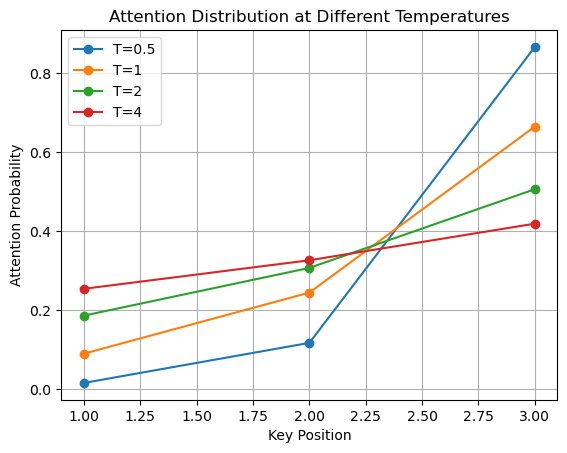

In [27]:

import numpy as np
import matplotlib.pyplot as plt

scores = np.array([1, 2, 3])
temperatures = [0.5, 1, 2, 4]

for T in temperatures:

    # Scale scores by temperature
    scaled = scores / T

    # Stable softmax
    exp_scores = np.exp(scaled - np.max(scaled))

    weights = exp_scores / np.sum(exp_scores)

    print("Temperature:", T)
    print("Attention weights:", weights)

    plt.plot(range(1, 4), weights, marker='o', label=f"T={T}")

plt.xlabel("Key Position")
plt.ylabel("Attention Probability")
plt.title("Attention Distribution at Different Temperatures")
plt.legend()
plt.grid()
plt.show()

The above graph shows how changing temperature affects attention probabilities.
* At T = 0.5, attention is very sharp and focuses mostly on Key 3.
* At T = 1, attention is moderately sharp.
* At T = 2, attention becomes more distributed.
* At T = 4, attention becomes relatively uniform.

### Question 8. Transformer Encoder Block from Scratch

**b. Python implementation** Implement a post-normalization encoder block in NumPy without 
dropout. Normalize each token across features, reusing your multi-head attention.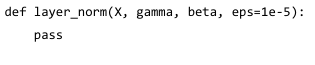 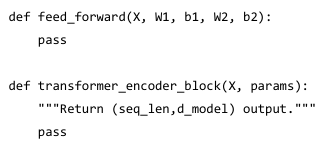

We implement three functions using NumPy:
* layer_norm() – normalizes each token across its features.
* feed_forward() – applies Linear → ReLU → Linear.
* transformer_encoder_block() – combines attention, residual connections, and normalization.

In [28]:
import numpy as np

# 1. Layer Normalization
def layer_norm(X, gamma, beta, eps=1e-5): 
    ''' gamma = Learnable scaling parameter, beta = Learnable scaling parameter, eps = constant to prevent division by zero'''

    # Mean and variance across features
    mean = np.mean(X, axis=-1, keepdims=True) # Mean
    var = np.var(X, axis=-1, keepdims=True) # Variance

    # Normalize
    X_norm = (X - mean) / np.sqrt(var + eps)

    # Scale and shift
    return gamma * X_norm + beta # Scales the normalized values, and shifts the normalized values.

In [29]:
# 2. Feed Forward Network
def feed_forward(X, W1, b1, W2, b2):

    # First linear transformation
    hidden = X @ W1 + b1 # Dot product between input matrix(X) and W1

    # ReLU activation
    hidden = np.maximum(0, hidden)

    # Second linear transformation
    output = hidden @ W2 + b2

    return output

In [30]:
# 3. Transformer Encoder Block
def transformer_encoder_block(X, params):
    """
    Return (seq_len, d_model) output.
    Assumes multi_head_attention() from Question 6
    is already defined.
    """

    # Multi-head self-attention
    attn_output, weights = multi_head_attention(
        X,
        params["W_Q"],
        params["W_K"],
        params["W_V"],
        params["W_O"],
        params["num_heads"]
    )

    # Residual connection + Layer Normalization
    X1 = layer_norm(
        X + attn_output,
        params["gamma1"],
        params["beta1"]
    )

    # Feed Forward Network
    ffn_output = feed_forward(
        X1,
        params["W1"],
        params["b1"],
        params["W2"],
        params["b2"]
    )

    # Residual connection + Layer Normalization
    output = layer_norm(
        X1 + ffn_output,
        params["gamma2"],
        params["beta2"]
    )

    return output

In [31]:
# 4. Example Execution
np.random.seed(42)

seq_len = 5
d_model = 8
num_heads = 2
d_ff = 16

X = np.random.randn(seq_len, d_model)

In [32]:
# Initialize parameters
params = {
    'W_Q': np.random.randn(d_model, d_model) * 0.1,
    'W_K': np.random.randn(d_model, d_model) * 0.1,
    'W_V': np.random.randn(d_model, d_model) * 0.1,
    'W_O': np.random.randn(d_model, d_model) * 0.1,

    'W1': np.random.randn(d_model, d_ff) * 0.1,
    'b1': np.zeros(d_ff),

    'W2': np.random.randn(d_ff, d_model) * 0.1,
    'b2': np.zeros(d_model),

    'gamma1': np.ones(d_model),
    'beta1': np.zeros(d_model),

    'gamma2': np.ones(d_model),
    'beta2': np.zeros(d_model),

    'num_heads': num_heads
}

In [33]:
# Run encoder block
output = transformer_encoder_block(X, params)

In [34]:
# Display result
print("Input Shape:", X.shape)
print("Output Shape:", output.shape)
print("\nEncoder Output:\n", output)

Input Shape: (5, 8)
Output Shape: (5, 8)

Encoder Output:
 [[-0.07760224 -0.96355805  0.08632835  1.40603525 -1.06664592 -1.22266559
   1.53513201  0.30297618]
 [ 0.04377297  1.37344226  0.13129388  0.0661355   1.20951459 -1.74855194
  -1.24180249  0.16619524]
 [-0.68518385  0.67351018 -0.58672755 -1.0542939   2.12318786  0.06537103
   0.4267876  -0.96265137]
 [-0.51463196  0.31023402 -1.22994405  0.6165987  -0.50623406 -0.37803295
  -0.54510953  2.24711984]
 [ 0.44359968 -0.49422859  1.44121488 -0.81014291  0.90616029 -1.6513951
  -0.71247625  0.87726801]]


### Question 9: Transformer Decoder Block and Complete Architecture

**b. Python implementation** Build a post-normalization decoder block with (1) masked self attention, (2) residual + normalization, (3) cross-attention, (4) residual + normalization, (5) FFN, (6) residual + normalization. Use d_model = 8, two heads, encoder length 5, decoder length 3; verify all tensor dimensions. Extend/reuse your multi-head implementation to support cross-attention and causal masking.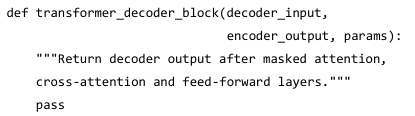

In [35]:
import numpy as np

# Layer Normalization
def layer_norm(X, gamma, beta, eps=1e-5):
    mean = np.mean(X, axis=-1, keepdims=True) # Mean
    var = np.var(X, axis=-1, keepdims=True) # Variance

    X_norm = (X - mean) / np.sqrt(var + eps)

    return gamma * X_norm + beta

In [36]:
# Generalized Multi-Head Attention
# Supports self-attention and cross-attention masking
def multi_head_attention(query_states, key_value_states,
                         W_Q, W_K, W_V, W_O,
                         num_heads, causal=False):

    seq_len_q, d_model = query_states.shape
    seq_len_k = key_value_states.shape[0]

    head_dim = d_model // num_heads
    
    assert d_model % num_heads == 0

    # Step 1: Project Q, K and V
    Q = query_states @ W_Q
    K = key_value_states @ W_K
    V = key_value_states @ W_V

    # Step 2: Split into multiple heads
    Q = Q.reshape(seq_len_q, num_heads, head_dim).transpose(1, 0, 2)
    K = K.reshape(seq_len_k, num_heads, head_dim).transpose(1, 0, 2)
    V = V.reshape(seq_len_k, num_heads, head_dim).transpose(1, 0, 2)

    # Step 3: Scaled dot-product attention
    scores = (Q @ K.transpose(0, 2, 1)) / np.sqrt(head_dim)

    # Step 4: Apply causal mask for decoder self-attention if required
    if causal:   # Check whether causal masking is enabled
        mask = np.triu(np.ones((seq_len_q, seq_len_k), dtype=bool),k=1) # Create the causal mask
        scores = np.where(mask == 1, -np.inf, scores) # Apply the causal mask

   # Step 5: Apply softmax
    scores = scores - np.max(scores, axis=-1, keepdims=True)

    exp_scores = np.exp(scores)

    attention_weights = exp_scores / np.sum(exp_scores, axis=-1, keepdims=True)

   # Step 6: Attention output
    head_outputs = attention_weights @ V

   # Step 7: Concatenate heads
    concatenated = head_outputs.transpose(1, 0, 2).reshape(seq_len_q, d_model)

    # Output projection
    output = concatenated @ W_O # Dot product between output and output projection weight matrix

    return output, attention_weights

In [37]:
# Feed Forward Network
def feed_forward(X, W1, b1, W2, b2):

    hidden = X @ W1 + b1
    hidden = np.maximum(0, hidden)  # ReLU

    output = hidden @ W2 + b2
    
    return output

In [38]:
# Transformer Decoder Block
def transformer_decoder_block(decoder_input, encoder_output, params):
    """
    Return decoder output after:
    1. Masked self-attention
    2. Residual + normalization
    3. Cross-attention
    4. Residual + normalization
    5. Feed-forward network
    6. Residual + normalization
    """


    # 1. Masked Multi-Head Self-Attention
    self_attn_output, self_weights = multi_head_attention(
        decoder_input,
        decoder_input,
        params['WQ_self'],
        params['WK_self'],
        params['WV_self'],
        params['WO_self'],
        params['num_heads'],
        causal=True
    )

    # 2. Residual + Layer Normalization
    X1 = layer_norm(
        decoder_input + self_attn_output,
        params["gamma1"],
        params["beta1"]
    )

    # 3. Cross-attention
    cross_attn_output, cross_weights = multi_head_attention(
        X1,
        encoder_output,
        params["WQ_cross"],
        params["WK_cross"],
        params["WV_cross"],
        params["WO_cross"],
        params['num_heads'],
        causal=False
    )

    # 4. Residual + Layer Normalization
    X2 = layer_norm(
        X1 + cross_attn_output,
        params["gamma2"],
        params["beta2"]
    )

    # 5. Feed Forward Network
    ffn_output = feed_forward(
        X2,
        params["W1"],
        params["b1"],
        params["W2"],
        params["b2"]
    )

    # 6. Residual + Layer Normalization
    output = layer_norm(
        X2 + ffn_output,
        params["gamma3"],
        params["beta3"]
    )

    return output, self_weights, cross_weights

In [39]:
# Testing and dimension verification

np.random.seed(42)

d_model = 8
num_heads = 2
d_ff = 16

encoder_len = 5
decoder_len = 3

# Encoder and decoder inputs
encoder_output = np.random.randn(encoder_len, d_model)
decoder_input = np.random.randn(decoder_len, d_model)

In [40]:
# Initialize parameters
params = {
    
    # Self-attention weights
    "WQ_self": np.random.randn(d_model, d_model) * 0.1,
    "WK_self": np.random.randn(d_model, d_model) * 0.1,
    "WV_self": np.random.randn(d_model, d_model) * 0.1,
    "WO_self": np.random.randn(d_model, d_model) * 0.1,

    # Cross-attention weights
    "WQ_cross": np.random.randn(d_model, d_model) * 0.1,
    "WK_cross": np.random.randn(d_model, d_model) * 0.1,
    "WV_cross": np.random.randn(d_model, d_model) * 0.1,
    "WO_cross": np.random.randn(d_model, d_model) * 0.1,

    # Feed-forward weights
    "W1": np.random.randn(d_model, d_ff) * 0.1,
    "b1": np.zeros(d_ff),
    "W2": np.random.randn(d_ff, d_model) * 0.1,
    "b2": np.zeros(d_model),

    # Layer normalization parameters
    "gamma1": np.ones(d_model),
    "beta1": np.zeros(d_model),

    "gamma2": np.ones(d_model),
    "beta2": np.zeros(d_model),

    "gamma3": np.ones(d_model),
    "beta3": np.zeros(d_model),
    
    'num_heads': num_heads
}

In [41]:
# Run decoder block
output, self_weights, cross_weights = transformer_decoder_block(
    decoder_input,
    encoder_output,
    params
)

In [42]:
# Verify dimensions
print("Encoder output shape:", encoder_output.shape)
print("Decoder input shape:", decoder_input.shape)

print("\nSelf-attention weights:", self_weights.shape)
print("Cross-attention weights:", cross_weights.shape)

print("\nFinal decoder output:", output.shape)

# Verify attention normalization
print("\nSelf-Attention Row Sums:")
print(self_weights.sum(axis=-1))

print("\nCross-Attention Row Sums:")
print(cross_weights.sum(axis=-1))

Encoder output shape: (5, 8)
Decoder input shape: (3, 8)

Self-attention weights: (2, 3, 3)
Cross-attention weights: (2, 3, 5)

Final decoder output: (3, 8)

Self-Attention Row Sums:
[[1. 1. 1.]
 [1. 1. 1.]]

Cross-Attention Row Sums:
[[1. 1. 1.]
 [1. 1. 1.]]


### Question 10. Computational Complexity and Transformer Design Trade-offs

**b. Python impelementation** Benchmark attention at n ∈ {32,64,128,256,512}, d_model = 64, H = 4. Measure execution time and calculate theoretical attention-matrix memory; plot time versus sequence length.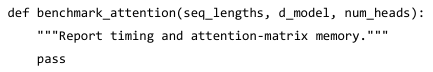 

In [43]:
import numpy as np
import time
import matplotlib.pyplot as plt

In [44]:
# 1. Simple attention function
def attention(Q, K, V):
    scores = Q @ K.transpose(0, 2, 1) / np.sqrt(Q.shape[-1])

    scores = scores - np.max(scores, axis=-1, keepdims=True)

    weights = np.exp(scores)
    weights = weights / np.sum(weights, axis=-1, keepdims=True)

    return weights @ V

In [45]:
# 2. Benchmark function
def benchmark_attention(seq_lengths, d_model, num_heads):

    times = []
    memories = []
    head_dim = d_model // num_heads

    for n in seq_lengths:

        # Generate random Q, K, V
        Q = np.random.randn(num_heads, n, head_dim).astype(np.float32)
        K = np.random.randn(num_heads, n, head_dim).astype(np.float32)
        V = np.random.randn(num_heads, n, head_dim).astype(np.float32)

        # Measure execution time
        start = time.perf_counter()  # Returns start timer value in seconds
        output = attention(Q, K, V)
        end = time.perf_counter()  # Returns start timer value in seconds

        avg_time = (end - start) * 1000 # Average time
        times.append(avg_time)
        
        # Calculate attention matrix memory in MB
        memory_bytes = (num_heads * n * n * 4)
        memory_mb = memory_bytes / (1024 ** 2)
        memories.append(memory_mb)

        print("Sequence length:", n)
        print(f"Execution time: {avg_time:.4f} ms")
        print(f"Attention memory: {memory_mb:.4f} MB")
        print("--------------------------")

    # Plot execution time
    plt.figure(figsize=(8, 5))
    plt.plot(seq_lengths, times, marker='o', label='Execution Time')
    plt.xlabel("Sequence Length (n)")
    plt.ylabel("Execution Time (ms)")
    plt.title("Attention Execution Time vs Sequence Length")
    plt.grid()
    plt.legend()
    plt.show()

    return times, memories

Sequence length: 32
Execution time: 0.5359 ms
Attention memory: 0.0156 MB
--------------------------
Sequence length: 64
Execution time: 1.6010 ms
Attention memory: 0.0625 MB
--------------------------
Sequence length: 128
Execution time: 3.2101 ms
Attention memory: 0.2500 MB
--------------------------
Sequence length: 256
Execution time: 8.4230 ms
Attention memory: 1.0000 MB
--------------------------
Sequence length: 512
Execution time: 41.6857 ms
Attention memory: 4.0000 MB
--------------------------


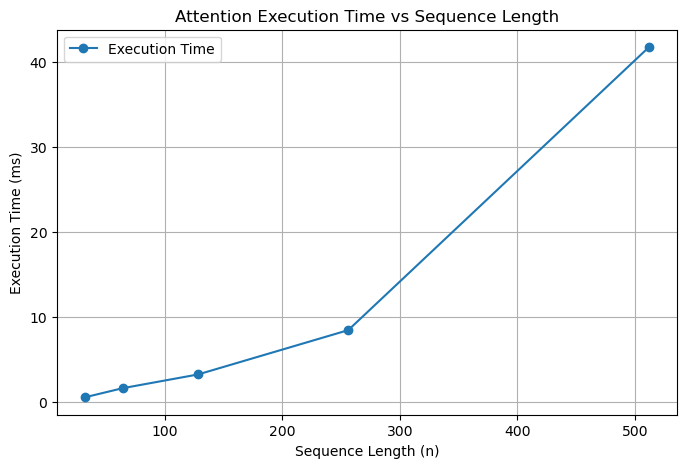

In [46]:
# Run experiment
seq_lengths = [32, 64, 128, 256, 512]

times, memories = benchmark_attention(seq_lengths, d_model=64, num_heads=4)

Observation:
- When sequence length doubles, attention matrix memory increases approximately four times.
- Execution time generally increases as sequence length increases.
- The experiment demonstrates the quadratic complexity of attention.